# Words to Pictures: SMS Spam and Ham
**Text visualization project**

Primary question: What language patterns distinguish spam from ham in this historical SMS corpus, and what should a filtering team do with this evidence? Sub-questions compare distinctive vocabulary, message length, and original message context.

The UCI SMS Spam Collection includes original message text and spam/ham labels. This project uses EDA, regex tokenization, lowercasing, stop-word removal, Porter stemming, a bag-of-words document-term matrix (DTM), TF-IDF, group comparisons, and keyword-in-context (KWIC). Results describe this historical convenience corpus; they are not causal or current-population estimates.

| Question | Evidence |
|---|---|
| Primary: language patterns and practical priorities | TF-IDF contrast, prevalence, KWIC |
| Which terms are distinctive? | DTM and label-specific TF-IDF |
| How do length/context vary? | Length distributions and KWIC |

## Dataset and ethics
The included CSV is converted from UCI Machine Learning Repository, SMS Spam Collection, DOI [10.24432/C5CC84](https://doi.org/10.24432/C5CC84), CC BY 4.0. UCI describes 5,574 messages. Accessed 2026-10-27. Empty text/invalid labels excluded; exact duplicates retained; sequential IDs generated. Messages may contain personal content, so only small samples and short snippets are shown. No dates, senders, or ratings exist. Attribution and license are documented in references.

Run all cells top-to-bottom. Relative paths read the included CSV and generate figures, summary, and PDF. No model download is needed.

In [1]:
from pathlib import Path
import re,numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from nltk.stem import PorterStemmer
from IPython.display import display
R=Path.cwd()
if not (R/"text_dataset.csv").exists():
 found=list(R.glob("**/text_dataset.csv"))
 if not found:raise FileNotFoundError("Start Jupyter in project folder or parent")
 R=found[0].parent
F=R/"outputs"/"figures";F.mkdir(parents=True,exist_ok=True);(R/"report").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi":120,"savefig.dpi":180,"axes.spines.top":False,"axes.spines.right":False});sns.set_theme(style="whitegrid",palette="colorblind")


## 1. Load, validate, clean
One document is one SMS. We preserve the original message for KWIC and inspect missing values, duplicates, and labels.

In [2]:
df=pd.read_csv(R/"text_dataset.csv",dtype={"message_id":"string","label":"string","message":"string"})
assert {"message_id","label","message"}.issubset(df.columns) and set(df.label.dropna().unique())<={"ham","spam"}
n0=len(df);missing=int(df.message.isna().sum());empty=int(df.message.fillna("").str.strip().eq("").sum());dups=int(df.message.duplicated().sum())
df=df.dropna(subset=["label","message"]).copy();df=df[df.message.str.strip().ne("")].copy()
df["word_count"]=df.message.str.findall(r"\b\w+\b").str.len();df["char_count"]=df.message.str.len()
words=int(df.word_count.sum());counts=df.label.value_counts().reindex(["ham","spam"]);pct=counts/len(df)
print(f"{n0:,} raw; {len(df):,} analyzed; missing={missing}; empty={empty}; duplicate texts retained={dups}; word count={words:,}")
display(df.head());display(pd.DataFrame({"dtype":df.dtypes.astype(str),"missing":df.isna().sum()}));display(counts)
assert len(df)>=50 and words>=3000


5,574 raw; 5,574 analyzed; missing=0; empty=0; duplicate texts retained=403; word count=90,381


,message_id,label,message,word_count,char_count
0,SMS0001,ham,"Go until jurong point, crazy.. Available only ...",20,111
1,SMS0002,ham,Ok lar... Joking wif u oni...,6,29
2,SMS0003,spam,Free entry in 2 a wkly comp to win FA Cup fina...,33,155
3,SMS0004,ham,U dun say so early hor... U c already then say...,11,49
4,SMS0005,ham,"Nah I don't think he goes to usf, he lives aro...",14,61


,dtype,missing
message_id,string,0
label,string,0
message,string,0
word_count,int64,0
char_count,Int64,0


label
ham     4827
spam     747
Name: count, dtype: Int64

### Data dictionary
message_id = generated row ID; label = source ham/spam; message = original text; word_count and char_count = derived lengths. Only empty text and missing values are removed. Duplicate texts remain and may not be independent.

## 2. Distribution and message length
Class imbalance makes within-group rates important.

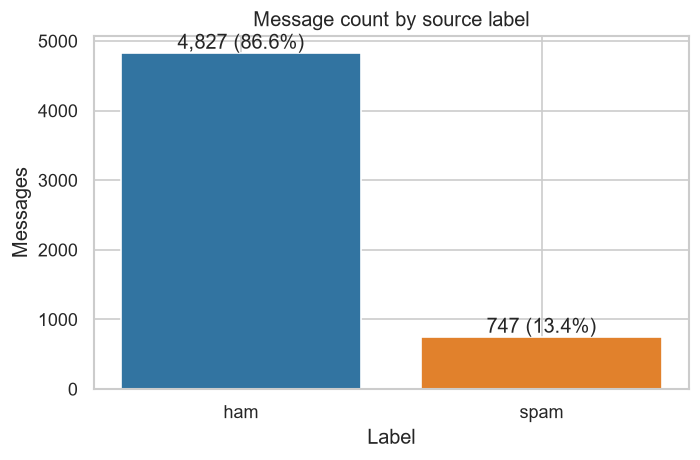

Interpretation: 4,827 ham (86.6%), 747 spam (13.4%). Counts are imbalanced; source labels are inherited, not independently verified.


In [3]:
fig,ax=plt.subplots(figsize=(6,4));b=ax.bar(counts.index,counts.values,color=["#3274A1","#E1812C"]);ax.bar_label(b,labels=[f"{n:,} ({p:.1%})" for n,p in zip(counts,pct)]);ax.set(title="Message count by source label",xlabel="Label",ylabel="Messages");fig.tight_layout();fig.savefig(F/"01_label_distribution.png",bbox_inches="tight");plt.show()
print(f"Interpretation: {counts.ham:,} ham ({pct.ham:.1%}), {counts.spam:,} spam ({pct.spam:.1%}). Counts are imbalanced; source labels are inherited, not independently verified.")


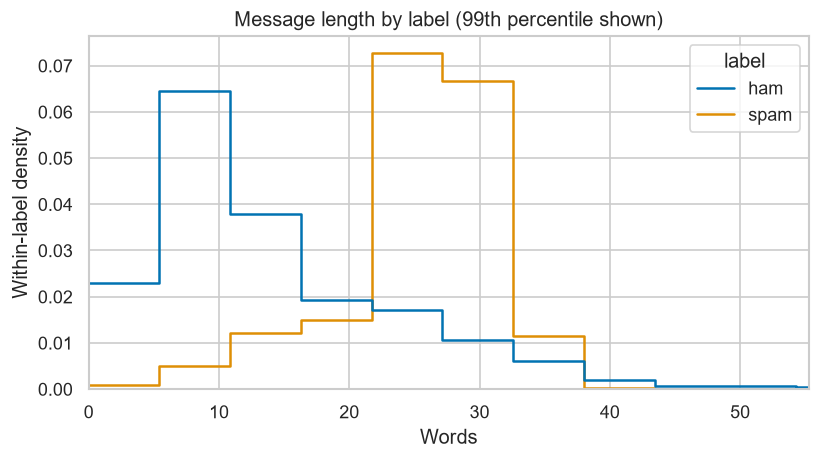

,count,median,mean
label,,,
ham,4827,11.0,14.780402
spam,747,27.0,25.483266


Interpretation: median length: ham 11, spam 27. Plot clips longest 1% for readability; all records remain. Length alone does not establish spam.


In [4]:
fig,ax=plt.subplots(figsize=(7,4));sns.histplot(data=df,x="word_count",hue="label",bins=35,stat="density",common_norm=False,element="step",fill=False,ax=ax);ax.set(xlim=(0,df.word_count.quantile(.99)),title="Message length by label (99th percentile shown)",xlabel="Words",ylabel="Within-label density");fig.tight_layout();fig.savefig(F/"02_message_length.png",bbox_inches="tight");plt.show()
med=df.groupby("label").word_count.median();display(df.groupby("label").word_count.agg(["count","median","mean"]));print(f"Interpretation: median length: ham {med.ham:.0f}, spam {med.spam:.0f}. Plot clips longest 1% for readability; all records remain. Length alone does not establish spam.")


## 3. Text preprocessing
Regex tokenization keeps alphabetic tokens and internal apostrophes. We lowercase, remove the explicit compact function-word list in the code while retaining negations (no/nor/not/never), then use NLTK Porter stemming. Digits and punctuation remain in original text but not normalized terms. Stemming consolidates inflections but can reduce readability. The list is documented in code; no external language resources are needed.

In [5]:
stem=PorterStemmer();stop=set("a an and are as at be been being but by for from had has have he her hers him his how i if in into is it its me my of on or our ours she so than that the their them they this those through to too up us was we were what when where which who will with would you your".split());rx=re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?")
def tokens(s):return [x.lower() for x in rx.findall(str(s))]
def clean(s):return [stem.stem(x) for x in tokens(s) if x not in stop]
df["lower_tokens"]=df.message.map(tokens);df["processed_tokens"]=df.message.map(clean);df["processed_text"]=df.processed_tokens.map(" ".join)
ex=df.sample(5,random_state=42)[["message_id","message","lower_tokens","processed_text"]].copy();ex["lower_tokens"]=ex.lower_tokens.map(" ".join);display(ex)
print("Negation is retained; function words are removed; inflections stemmed. Original is unmodified.")
assert df.processed_tokens.map(len).gt(0).mean()>.95


,message_id,message,lower_tokens,processed_text
3690,SMS3691,You still coming tonight?,you still coming tonight,still come tonight
3527,SMS3528,"""HEY BABE! FAR 2 SPUN-OUT 2 SPK AT DA MO... DE...",hey babe far spun out spk at da mo dead da wrl...,hey babe far spun out spk da mo dead da wrld s...
724,SMS0725,Ya even those cookies have jelly on them,ya even those cookies have jelly on them,ya even cooki jelli
3370,SMS3371,Sorry i've not gone to that place. I.ll do so ...,sorry i've not gone to that place i ll do so t...,sorri i'v not gone place ll do tomorrow realli...
468,SMS0469,When are you going to ride your bike?,when are you going to ride your bike,go ride bike


Negation is retained; function words are removed; inflections stemmed. Original is unmodified.


## 4. DTM and TF-IDF
A DTM has documents as rows, terms as columns, and occurrence counts in cells. TF-IDF weights terms by within-document use and inverse collection frequency. Scores are relative weights, not probabilities.

In [6]:
from collections import Counter
import math
doc_counts=[Counter(x) for x in df.processed_tokens]
terms=np.array(sorted({t for d in doc_counts for t in d}))
term_id={t:i for i,t in enumerate(terms)}
freq=np.zeros(len(terms),dtype=np.int64)
dfreq=np.zeros(len(terms),dtype=np.int64)
for d in doc_counts:
 for t,count in d.items():
  k=term_id[t];freq[k]+=count;dfreq[k]+=1
print(f"DTM dimensions: {len(doc_counts):,} documents × {len(terms):,} terms; nonzero cells {sum(map(len,doc_counts)):,}")
ix=freq.argsort()[::-1][:12]
display(pd.DataFrame([{terms[k]:d.get(terms[k],0) for k in ix} for d in doc_counts[:5]],index=df.message_id.iloc[:5]))
assert len(doc_counts)==len(df)
idf=np.log((1+len(df))/(1+dfreq))+1
weighted=[]
for d in doc_counts:
 row={term_id[t]:(1+math.log(count))*idf[term_id[t]] for t,count in d.items()}
 norm=math.sqrt(sum(v*v for v in row.values()))
 weighted.append({k:v/norm for k,v in row.items()} if norm else {})
vocab=terms
avg_ham=np.zeros(len(terms));avg_spam=np.zeros(len(terms))
for label,row in zip(df.label,weighted):
 target=avg_ham if label=="ham" else avg_spam
 for k,v in row.items():target[k]+=v
avg_ham/=int((df.label=="ham").sum());avg_spam/=int((df.label=="spam").sum())
avg=pd.DataFrame({"term":terms,"ham":avg_ham,"spam":avg_spam});avg["diff"]=avg.spam-avg.ham
print(f"TF-IDF dimensions: {len(df):,} × {len(terms):,}; finite normalized values: {all(np.isfinite(list(x.values())).all() for x in weighted)}")
first_spam=int(np.flatnonzero(df.label.to_numpy()=="spam")[0]);row=weighted[first_spam];k=max(row,key=row.get)
print(f"Example highest TF-IDF term in {df.message_id.iloc[first_spam]}: {terms[k]}, score={row[k]:.3f}; this is not a spam probability.")


DTM dimensions: 5,574 documents × 6,524 terms; nonzero cells 54,841


,u,call,now,do,go,get,not,can,i'm,ur,no,just
message_id,,,,,,,,,,,,
SMS0001,0,0,0,0,1,0,0,0,0,0,0,0
SMS0002,1,0,0,0,0,0,0,0,0,0,0,0
SMS0003,0,0,0,0,0,0,0,0,0,0,0,0
SMS0004,2,0,0,0,0,0,0,0,0,0,0,0
SMS0005,0,0,0,0,0,0,0,0,0,0,0,0


TF-IDF dimensions: 5,574 × 6,524; finite normalized values: True
Example highest TF-IDF term in SMS0003: fa, score=0.447; this is not a spam probability.


## 5. Visual findings and group comparisons
All charts are exported; interpretations follow each chart.

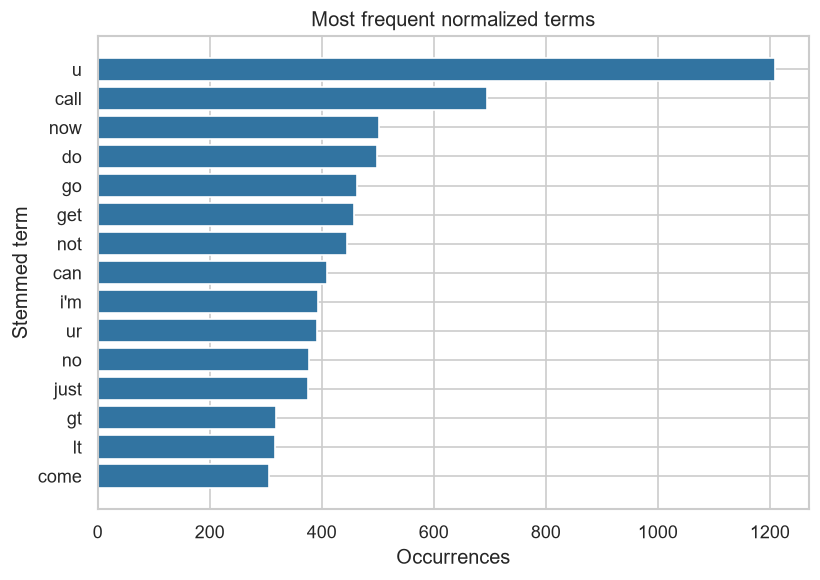

Interpretation: most frequent term u (1,209). Counts are term occurrences, not message share, and class imbalance affects them.


In [7]:
top=pd.DataFrame({"term":terms,"count":freq}).nlargest(15,"count").sort_values("count");fig,ax=plt.subplots(figsize=(7,5));ax.barh(top.term,top["count"],color="#3274A1");ax.set(title="Most frequent normalized terms",xlabel="Occurrences",ylabel="Stemmed term");fig.tight_layout();fig.savefig(F/"03_top_terms.png",bbox_inches="tight");plt.show()
print(f"Interpretation: most frequent term {terms[freq.argmax()]} ({freq.max():,}). Counts are term occurrences, not message share, and class imbalance affects them.")


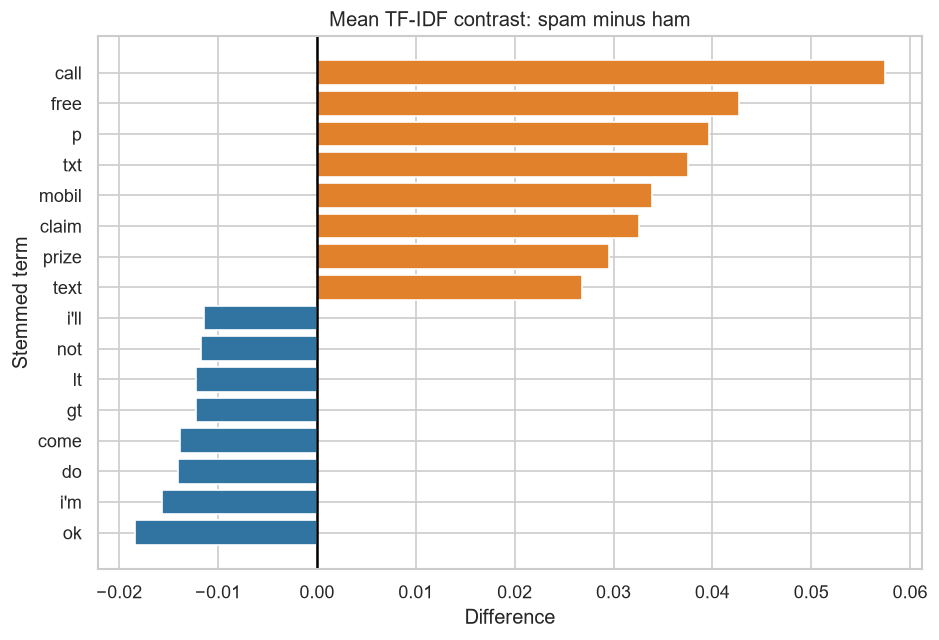

Interpretation: positive leader call (0.0574); negative leader ok (-0.0184). Descriptive, not classifier accuracy; rare terms may rank highly.


In [8]:
contrast=pd.concat([avg.nlargest(8,"diff"),avg.nsmallest(8,"diff")]).drop_duplicates("term").sort_values("diff");fig,ax=plt.subplots(figsize=(8,5.5));ax.barh(contrast.term,contrast["diff"],color=["#3274A1" if x<0 else "#E1812C" for x in contrast["diff"]]);ax.axvline(0,color="black");ax.set(title="Mean TF-IDF contrast: spam minus ham",xlabel="Difference",ylabel="Stemmed term");fig.tight_layout();fig.savefig(F/"04_tfidf_contrast.png",bbox_inches="tight");plt.show()
pos=avg.loc[avg["diff"].idxmax()];neg=avg.loc[avg["diff"].idxmin()];print(f"Interpretation: positive leader {pos.term} ({pos['diff']:.4f}); negative leader {neg.term} ({neg['diff']:.4f}). Descriptive, not classifier accuracy; rare terms may rank highly.")


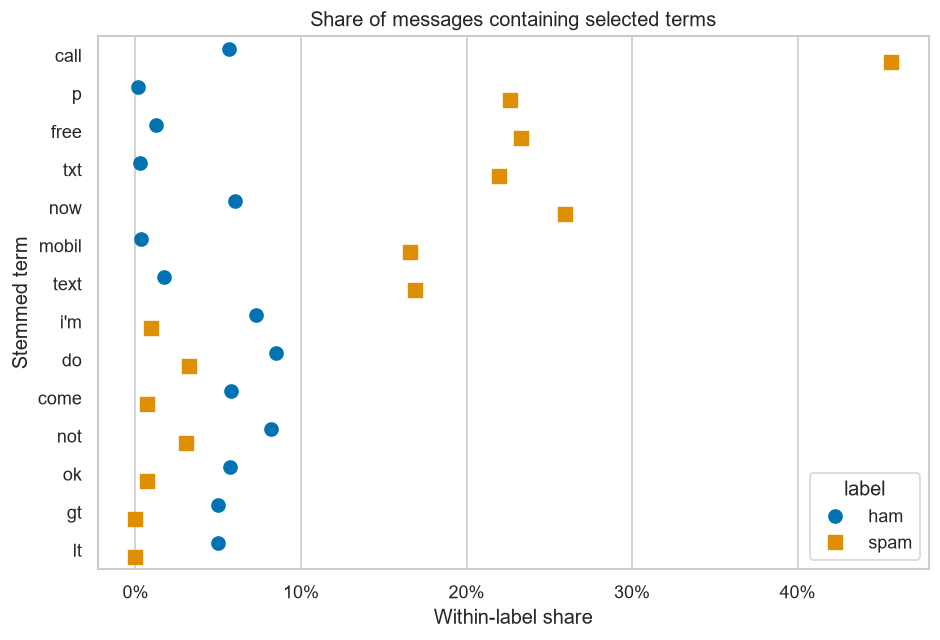

Interpretation: largest plotted prevalence gap call: spam 45.6%, ham 5.6%, difference +40.0%. Presence counted once per message.


In [9]:
rates={}
for lab in ["ham","spam"]:
 sums=np.zeros(len(terms));group=df.label.to_numpy()==lab
 for d in [doc_counts[i] for i in np.flatnonzero(group)]:
  for t in d:sums[term_id[t]]+=1
 rates[lab]=sums/int(group.sum())
pr=pd.DataFrame({"term":terms,"ham":rates["ham"],"spam":rates["spam"]});pr["diff"]=pr.spam-pr.ham
sel=pd.concat([pr.nlargest(7,"diff"),pr.nsmallest(7,"diff")]).drop_duplicates("term");long=sel.melt(id_vars="term",value_vars=["ham","spam"],var_name="label",value_name="share")
fig,ax=plt.subplots(figsize=(8,5.5));sns.pointplot(data=long,x="share",y="term",hue="label",dodge=.35,markers=["o","s"],linestyles="none",ax=ax);ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f"{x:.0%}"));ax.set(title="Share of messages containing selected terms",xlabel="Within-label share",ylabel="Stemmed term");fig.tight_layout();fig.savefig(F/"05_group_prevalence.png",bbox_inches="tight");plt.show()
key=pr.iloc[pr["diff"].abs().argmax()];print(f"Interpretation: largest plotted prevalence gap {key.term}: spam {key.spam:.1%}, ham {key.ham:.1%}, difference {key['diff']:+.1%}. Presence counted once per message.")


## 6. KWIC context
Keyword-in-context shows original wording around the leading spam-associated term. We cap at six first matches per label; examples are illustrative and may contain personal content.

,label,message_id,context
0,spam,SMS0009,…to receivea £900 prize reward! To claim <<cal...
1,spam,SMS0010,…st colour mobiles with camera for Free! <<Cal...
2,spam,SMS0043,…4351 - Rodger Burns - MSG = We tried to <<cal...
3,spam,SMS0057,…ear special cinema pass for 2 is yours. <<cal...
4,spam,SMS0066,"…u are awarded with a £1500 Bonus Prize, <<cal..."
5,spam,SMS0094,Please <<call>> our customer service represent...
6,ham,SMS0008,…e Nurungu Vettam)' has been set as your <<cal...
7,ham,SMS0046,No <<calls>>..messages..missed calls
8,ham,SMS0058,"Sorry, I'll <<call>> later in meeting."
9,ham,SMS0075,U can <<call>> me now...


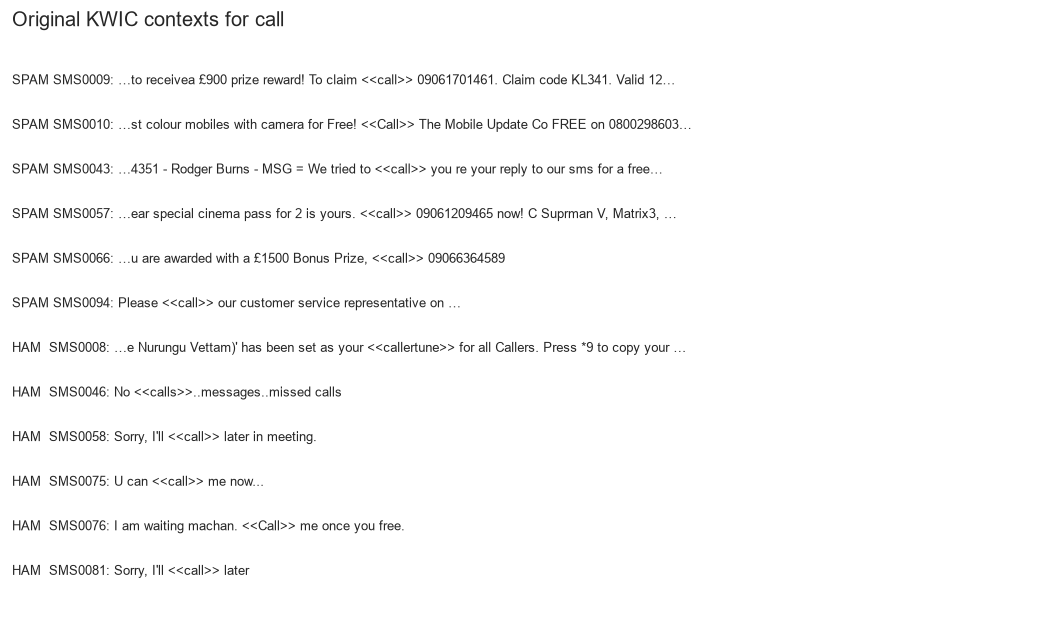

Interpretation: 12 short original contexts illustrate call; first matches are not representative and stemming may miss word variants.


In [10]:
term=str(pos.term);pat=re.compile(r"\b"+re.escape(term)+r"\w*\b",re.I)
def snippets(frame,n=6):
 out=[]
 for _,r in frame.iterrows():
  q=pat.search(r.message)
  if q:
   a=max(0,q.start()-40);b=min(len(r.message),q.end()+40);ctx=("…" if a else "")+r.message[a:q.start()]+"<<"+q.group()+">>"+r.message[q.end():b]+("…" if b<len(r.message) else "")
   out.append({"label":r.label,"message_id":r.message_id,"context":ctx})
   if len(out)>=n:break
 return out
kw=pd.DataFrame(snippets(df[df.label=="spam"])+snippets(df[df.label=="ham"]));display(kw)
fig,ax=plt.subplots(figsize=(9,max(3,.45*len(kw))));ax.axis("off");ax.set_title(f"Original KWIC contexts for {term}",loc="left")
for i,q in kw.reset_index(drop=True).iterrows():ax.text(0,1-(i+1)/(len(kw)+1),f"{q.label.upper():4} {q.message_id}: {q.context}",fontsize=8,va="center",wrap=True)
fig.tight_layout();fig.savefig(F/"06_kwic_context.png",bbox_inches="tight");plt.show()
print(f"Interpretation: {len(kw)} short original contexts illustrate {term}; first matches are not representative and stemming may miss word variants.")


## 7. Evaluation and recommendations

**Figure 4:** The zero-centered TF-IDF contrast is interpretable and faithful to the stated corpus calculation. Trust is limited by dataset age, convenience sampling, inherited labels, and stemming. Current held-out data and uncertainty intervals would improve trust.

**Figure 5:** The percentage scale is direct and counts message-level presence faithfully, though duplicate messages may not be independent. Terms were selected on this corpus, so this is not predictive validation; held-out evaluation would reduce selection bias.

1. Use contrasting terms as human-review cues, then measure precision, recall, and false-positive rate on recent independently labeled messages before changing filters.
2. Contextually audit legitimate messages containing spam-associated cues and track false positives. Sender metadata is absent, so subgroup fairness is not measurable here.
3. Repeat the analysis on consented current data to monitor language drift.

Frequency and TF-IDF surface candidate cues; prevalence accounts for group size; KWIC shows original context. This supports evaluation, not automatic rules or causal claims.

## References and reproducibility
Almeida, T. A., Gómez Hidalgo, J. M., & Yamakami, A. (2011). *Contributions to the study of SMS spam filtering*. UCI SMS Spam Collection. https://doi.org/10.24432/C5CC84 (CC BY 4.0). Scikit-learn: https://scikit-learn.org/. NLTK: https://www.nltk.org/.

- [x] Real included corpus with source/license
- [x] Tokenization, lowercase, stop words, negation preservation, stemming
- [x] Five real records before/after; original kept
- [x] Validated DTM and TF-IDF
- [x] Six figures, group comparison, KWIC
- [x] Two visual evaluations; three actionable recommendations
- [x] Relative paths and deterministic sampling

## 8. Generate PDF report and summary
The final cell generates a concise report and summary from these results.

In [11]:
summary=pd.DataFrame([("messages",len(df)),("word_count",words),("ham",int(counts.ham)),("spam",int(counts.spam)),("dtm_terms",len(terms)),("tfidf_terms",len(vocab)),("spam_term",str(pos.term)),("ham_term",str(neg.term)),("gap_term",str(key.term)),("gap",f"{key['diff']:.4f}")],columns=["metric","value"]);summary.to_csv(R/"outputs"/"analysis_summary.csv",index=False)
from reportlab.lib.pagesizes import letter
from reportlab.lib.styles import getSampleStyleSheet,ParagraphStyle
from reportlab.lib.units import inch
from reportlab.platypus import SimpleDocTemplate,Paragraph,Image,PageBreak
S=getSampleStyleSheet();S.add(ParagraphStyle(name="Small",parent=S["BodyText"],fontSize=8,leading=9.5,spaceAfter=3));story=[]
def P(x,style="Small"):story.append(Paragraph(x,S[style]))
def H(x):story.append(Paragraph(x,S["Heading2"]))
def I(file,cap):story.extend([Image(str(F/file),width=6.3*inch,height=2.65*inch,kind="proportional"),Paragraph(cap,S["Small"])])
P("WORDS TO PICTURES","Title");P("SMS spam and ham language - Insight report","Heading2")
H("Executive summary");P(f"Analyzed {len(df):,} UCI messages: {counts.ham:,} ham, {counts.spam:,} spam, {words:,} word-boundary tokens. Largest plotted prevalence gap: {key.term}, {key.spam:.1%} of spam vs {key.ham:.1%} of ham ({key['diff']:+.1%}). These are historical corpus associations, not current detection accuracy. Use cues for human review, audit false positives, and refresh with current labels.")
H("Question, dataset, method");P("Primary question: what language distinguishes spam from ham and what should filtering teams prioritize? Sub-questions examine terms, length, and context. Source: UCI SMS Spam Collection, DOI 10.24432/C5CC84, CC BY 4.0, accessed 2026-10-27. Empty text/missing labels excluded; duplicates retained; generated IDs. Historical convenience corpus, not representative.")
P(f"Regex tokens, lowercase, stop-word removal preserving negations, Porter stemming; DTM {len(df):,} by {len(terms):,}; TF-IDF L2-normalized. Original text for KWIC.")
I("01_label_distribution.png",f"Figure 1. Ham {counts.ham:,} ({pct.ham:.1%}); spam {counts.spam:,} ({pct.spam:.1%}).");I("02_message_length.png",f"Figure 2. Median ham {med.ham:.0f}, spam {med.spam:.0f} words; display clipped at 99th percentile.")
story.append(PageBreak());H("Visual findings");P(f"Top positive mean TF-IDF contrast: {pos.term} ({pos['diff']:.4f}); most negative: {neg.term} ({neg['diff']:.4f}). Scores are not probabilities.")
I("03_top_terms.png","Figure 3. Frequent stemmed terms; raw counts reflect class imbalance.");I("04_tfidf_contrast.png","Figure 4. Mean TF-IDF contrast, spam minus ham.")
story.append(PageBreak());I("05_group_prevalence.png",f"Figure 5. Within-label message share; largest shown gap {key.term}: {key.spam:.1%} vs {key.ham:.1%}.");I("06_kwic_context.png",f"Figure 6. Short original contexts for {term}; first hits are illustrative.")
H("Trust, recommendations, conclusion");P("Figure 4 is interpretable with a zero-centered scale and faithful to the computation; trust is limited by age, sample, inherited labels, and stemming. Figure 5 has a clear proportion scale, but duplicates may not be independent and terms were selected on the same corpus. Neither validates prediction. Test on current held-out data.")
P("1. Use terms as human-review cues and evaluate precision, recall, false positives. 2. Contextually audit legitimate matches. 3. Repeat on consented current data to monitor drift. Sender fairness cannot be examined here. Results justify evaluation, not automatic rules or causation.")
H("References");P("Almeida et al. (2011). Contributions to the study of SMS spam filtering. UCI SMS Spam Collection. https://doi.org/10.24432/C5CC84. Scikit-learn: https://scikit-learn.org/. NLTK: https://www.nltk.org/.")
pdf=R/"report"/"Words_to_Pictures_Insight_Report.pdf";SimpleDocTemplate(str(pdf),pagesize=letter,rightMargin=.5*inch,leftMargin=.5*inch,topMargin=.35*inch,bottomMargin=.35*inch).build(story);print(f"PDF generated: {pdf}")


PDF generated: C:\Users\acj32\Documents\Codex\2026-10-27\do-t\outputs\Words_to_Pictures_Project\report\Words_to_Pictures_Insight_Report.pdf
